<a href="https://colab.research.google.com/github/renatobdo/doutorado/blob/main/01_extracao_dados_sim_obitos_dengue_2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip install pysus


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 239.4/239.4 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.7/247.7 kB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.5/63.5 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 888.3/888.3 kB 24.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 316.5/316.5 kB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.5/21.5 MB 52.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 68.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.3/58.3 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 67.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.2/46.2 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.0/

Documentação em https://pysus.readthedocs.io/en/latest/databases/data-sources.html

In [1]:
from pysus import sinan, sinasc, sim, sih, sia, pni, ibge, cnes, ciha

# Posso utilizar direto os dados da fonte em vez do pysus,
pois consigo utilizar dados mais atualizados. Infelizmente os dados mais atuais sobre mortalidade no Brasil são de 2 anos atrás. No caso do pysus existe um delay (pode ser o mesmo delay ou no caso limitação do SUS em informar esses dados). Vou trabalhar com os dados diretos da fonte. No caso: https://datasus.saude.gov.br/transferencia-de-arquivos/#  

 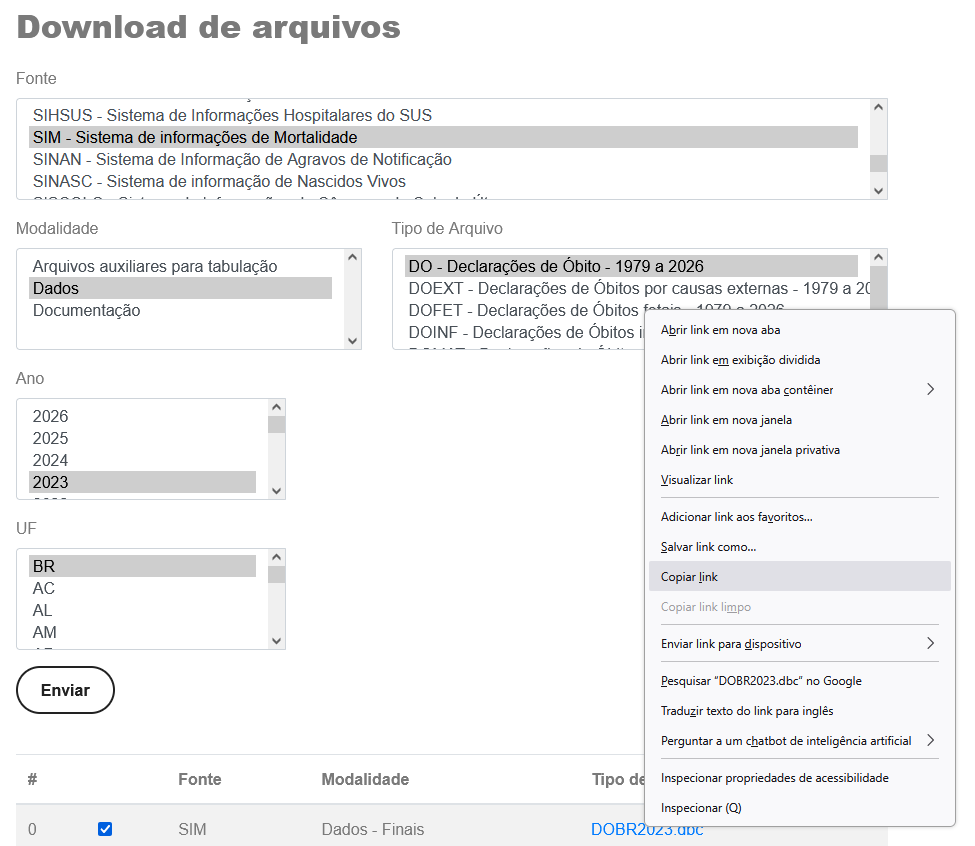

 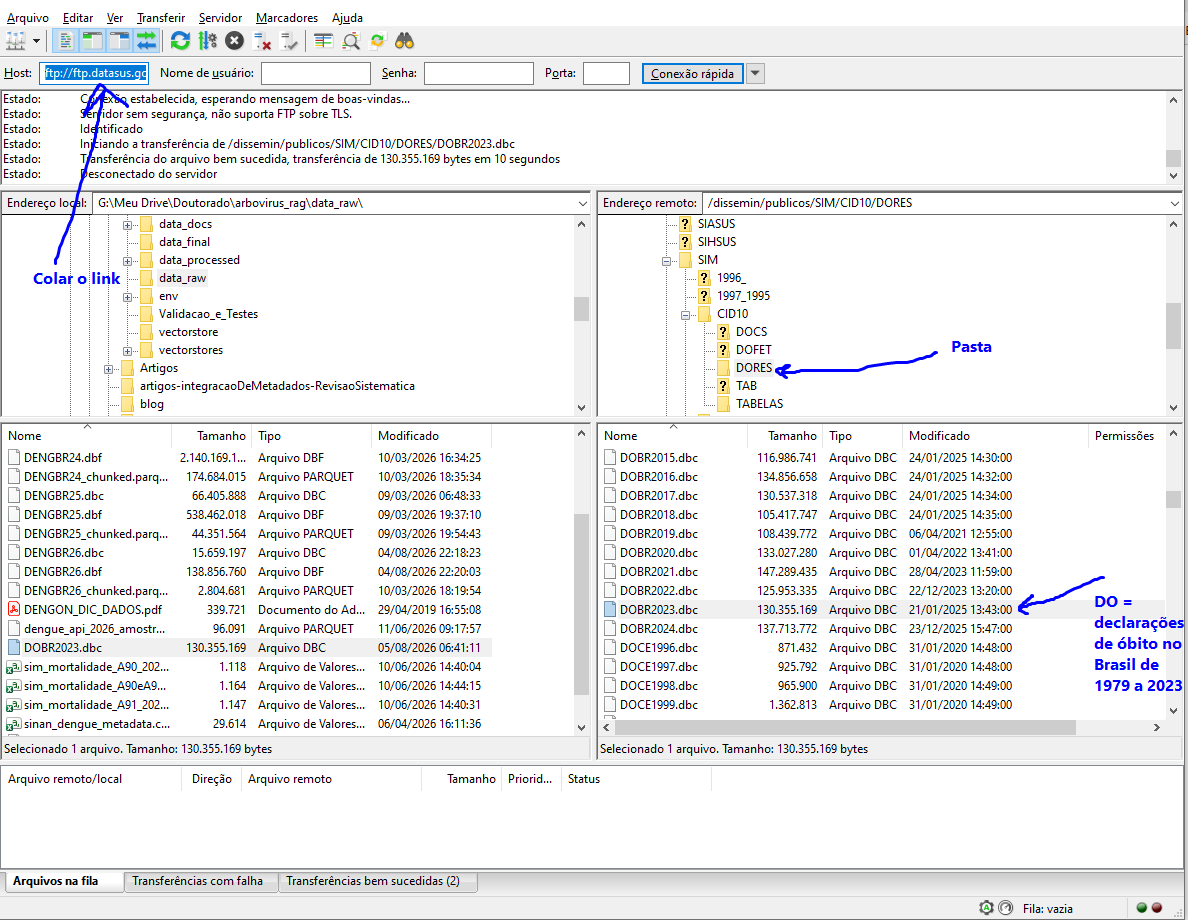

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Baixar o arquivo direto do site do SINAN. Para baixá-lo https://datasus.saude.gov.br/transferencia-de-arquivos/#  Tem que aguardar até aparecer um link chamado arquivo. Para ir mais rápido eu utilizei o filezilla é um cliente ftp, com isso, é só digitar ftp://ftp.datasus.gov.br/dissemin/publicos/SINAN/ no HOST e conectar. Clicar e arrastar para a esquerda (pasta destino) os arquivos do servidor. Por exemplo, o arquivo DENGBR24. Repare que como ainda estamos em 2026 os arquivos estão na pasta PRELIM e não na pasta FINAIS. Se for baixar dos outros anos por exemplo DENGBR24 utilize a pasta FINAIS ftp://ftp.datasus.gov.br/dissemin/publicos/SINAN/DADOS/FINAIS/DENGBR26.dbc

Conversão do arquivo .dbc para .dbf e utilização do dataframe df. Tive que ignorar esse código da célula 26 pois algumas bibliotecas não estão funcionando mais como #from pysus.preprocessing.decoders import decodifica_idade_SINAN e from pysus import dbc_to_dbf # Import the conversion function

In [3]:
!pip install datasus-dbc dbfread pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 12.9 MB/s eta 0:00:00


## Substitua o arquivo quando necessário,
pois você pode utilizar de outros anos. Se você já converteu de dbc para dbf não tem necessidade de executar o código abaixo novamente. Pule para ao próximo bloco de código.

In [ ]:
import os
import pandas as pd
from dbfread import DBF
import datasus_dbc

# Caminhos
input_dbc_path = '/content/drive/MyDrive/Doutorado/arbovirus_rag/data_raw/DOBR2023.dbc'
output_dbf_path = '/content/drive/MyDrive/Doutorado/arbovirus_rag/data_raw/DOBR2023.dbf'

# Verifica se o DBC existe
if not os.path.exists(input_dbc_path):
    raise FileNotFoundError(f"Arquivo DBC não encontrado: {input_dbc_path}")

# Cria diretório de saída
os.makedirs(os.path.dirname(output_dbf_path), exist_ok=True)

# Converte DBC para DBF
datasus_dbc.decompress(input_dbc_path, output_dbf_path)

print(f"Arquivo convertido com sucesso: {output_dbf_path}")


Arquivo convertido com sucesso: /content/drive/MyDrive/Doutorado/arbovirus_rag/data_raw/DOBR2023.dbf


## Explorando uma amostra dos dados (10 mil registros).
Caso queira ir direto para a quantidade real de dados pule esse bloco.

In [ ]:
import os
import shutil
import pandas as pd
from dbfread import DBF
from itertools import islice

drive_dbf_path = (
    "/content/drive/MyDrive/Doutorado/"
    "arbovirus_rag/data_raw/DOBR2023.dbf"
)

local_dbf_path = "/content/DOBR2023.dbf"

if not os.path.exists(local_dbf_path):
    shutil.copy2(drive_dbf_path, local_dbf_path)

table_dobr2023 = DBF(
    local_dbf_path,
    encoding="iso-8859-1",
    load=False
)

# Carrega somente 10 mil registros inicialmente
df_amostra_dobr2023 = pd.DataFrame(
    islice(table_dobr2023, 10_000)
)

print("Amostra carregada.")
print(df_amostra_dobr2023.shape)
print(df_amostra_dobr2023.columns.tolist())

df_amostra_dobr2023.head()

Amostra carregada.
(10000, 87)
['ORIGEM', 'TIPOBITO', 'DTOBITO', 'HORAOBITO', 'NATURAL', 'CODMUNNATU', 'DTNASC', 'IDADE', 'SEXO', 'RACACOR', 'ESTCIV', 'ESC', 'ESC2010', 'SERIESCFAL', 'OCUP', 'CODMUNRES', 'LOCOCOR', 'CODESTAB', 'ESTABDESCR', 'CODMUNOCOR', 'IDADEMAE', 'ESCMAE', 'ESCMAE2010', 'SERIESCMAE', 'OCUPMAE', 'QTDFILVIVO', 'QTDFILMORT', 'GRAVIDEZ', 'SEMAGESTAC', 'GESTACAO', 'PARTO', 'OBITOPARTO', 'PESO', 'TPMORTEOCO', 'OBITOGRAV', 'OBITOPUERP', 'ASSISTMED', 'EXAME', 'CIRURGIA', 'NECROPSIA', 'LINHAA', 'LINHAB', 'LINHAC', 'LINHAD', 'LINHAII', 'CAUSABAS', 'CB_PRE', 'COMUNSVOIM', 'DTATESTADO', 'CIRCOBITO', 'ACIDTRAB', 'FONTE', 'NUMEROLOTE', 'TPPOS', 'DTINVESTIG', 'CAUSABAS_O', 'DTCADASTRO', 'ATESTANTE', 'STCODIFICA', 'CODIFICADO', 'VERSAOSIST', 'VERSAOSCB', 'FONTEINV', 'DTRECEBIM', 'ATESTADO', 'DTRECORIGA', 'CAUSAMAT', 'ESCMAEAGR1', 'ESCFALAGR1', 'STDOEPIDEM', 'STDONOVA', 'DIFDATA', 'NUDIASOBCO', 'NUDIASOBIN', 'DTCADINV', 'TPOBITOCOR', 'DTCONINV', 'FONTES', 'TPRESGINFO', 'TPNIVELINV',

,ORIGEM,TIPOBITO,DTOBITO,HORAOBITO,NATURAL,CODMUNNATU,DTNASC,IDADE,SEXO,RACACOR,...,FONTES,TPRESGINFO,TPNIVELINV,NUDIASINF,DTCADINF,MORTEPARTO,DTCONCASO,FONTESINF,ALTCAUSA,CONTADOR
0,1,2,01012023,2015,841,412200,19051951,471,2,1,...,,,,,,,,,,1
1,1,2,01012023,0720,835,351492,08011945,477,2,1,...,,,,,,,,,,2
2,1,2,01012023,2300,822,220010,02091979,443,1,1,...,,,,,,,,,,3
3,1,2,01012023,0350,842,420810,04051932,490,2,1,...,,,,,,,,,,4
4,1,2,01012023,2150,835,350400,17122022,215,1,1,...,SXXXXX,,,,02022023,3,02022023,,2,5


## Agrupamento para verificar a causa básica dos óbitos

In [ ]:
obitos_por_cid = (
    df_amostra_dobr2023
    .groupby("CAUSABAS")
    .size()
    .reset_index(name="total_obitos")
    .sort_values("total_obitos", ascending=False)
)

obitos_por_cid.head(20)

,CAUSABAS,total_obitos
453,I219,675
918,R99,309
55,B342,306
586,J189,286
437,I10,249
524,I64,237
144,C349,191
321,E149,185
797,N390,183
391,G309,172


In [ ]:
df_amostra_dobr2023["CAUSABAS"] = (
    df_amostra_dobr2023["CAUSABAS"]
    .astype("string")
    .str.strip()
    .str.upper()
)

## Agrupamento da amostra para verificar os casos de dengue
 A90 (dengue clássica) e A91 (dengue hemorrágica)

In [ ]:
obitos_dengue_por_cid = (
    df_obitos_dengue
    .groupby("CAUSABAS")
    .size()
    .reset_index(name="total_obitos")
)

obitos_dengue_por_cid["descricao"] = (
    obitos_dengue_por_cid["CAUSABAS"]
    .map({
        "A90": "Dengue clássica",
        "A91": "Dengue hemorrágica"
    })
)

obitos_dengue_por_cid

,CAUSABAS,total_obitos,descricao
0,A91,1,Dengue hemorrágica


# Causa básica versus causa mencionada

Aqui não mais estou trabalhando com amostra.

Filtrar CAUSABAS responde à pergunta:

Quantos óbitos tiveram a dengue selecionada como causa básica?

Entretanto, a dengue também pode aparecer em outras partes da Declaração de Óbito, como: LINHAA
LINHAB
LINHAC
LINHAD
LINHAII

In [4]:
from dbfread import DBF
import pandas as pd

output_dbf_path = (
    "/content/drive/MyDrive/Doutorado/"
    "arbovirus_rag/data_raw/DOBR2023.dbf"
)

registros_dengue = []

table_dobr2023 = DBF(
    output_dbf_path,
    encoding="iso-8859-1",
    load=False
)

for registro in table_dobr2023:
    cid = str(registro.get("CAUSABAS", "")).strip().upper()

    if cid.startswith(("A90", "A91")):
        registros_dengue.append(registro)

df_obitos_dengue_2023 = pd.DataFrame(registros_dengue)

print("Leitura concluída.")
print(f"Total de óbitos por dengue: {len(df_obitos_dengue_2023)}")

df_obitos_dengue_2023.head()

Leitura concluída.
Total de óbitos por dengue: 1322


,ORIGEM,TIPOBITO,DTOBITO,HORAOBITO,NATURAL,CODMUNNATU,DTNASC,IDADE,SEXO,RACACOR,...,FONTES,TPRESGINFO,TPNIVELINV,NUDIASINF,DTCADINF,MORTEPARTO,DTCONCASO,FONTESINF,ALTCAUSA,CONTADOR
0,1,2,02012023,0550,829,290140,20011957,465,2,1,...,,,,,,,,,,4783
1,1,2,04012023,1352,829,292210,15051939,483,1,2,...,,,,,,,,,,15755
2,1,2,05012023,2037,832,320320,28121967,455,2,4,...,,,,,,,,,,19217
3,1,2,06012023,1940,824,240380,22021922,500,1,1,...,,,,,,,,,,21110
4,1,2,09012023,0756,832,320140,07091945,477,2,1,...,,,,,,,,,,34522


# Salva o filtro realizado no arquivo do SIM em um csv.
Filtra as mortes por casos de dengue. O chatgpt sugeriu também salvar em formato parquet.

In [5]:
output_csv = "/content/drive/MyDrive/Doutorado/arbovirus_rag/data_processed/obitos_dengue_2023.csv"

import os
os.makedirs(os.path.dirname(output_csv), exist_ok=True)

df_obitos_dengue_2023.to_csv(
    output_csv,
    index=False,
    encoding="utf-8-sig"
)

print(f"Arquivo salvo em: {output_csv}")

Arquivo salvo em: /content/drive/MyDrive/Doutorado/arbovirus_rag/data_processed/obitos_dengue_2023.csv


## salvando também em formato parquet

In [6]:
output_parquet = "/content/drive/MyDrive/Doutorado/arbovirus_rag/data_processed/obitos_dengue_2023.parquet"

df_obitos_dengue_2023.to_parquet(
    output_parquet,
    index=False
)

print(f"Arquivo salvo em: {output_parquet}")

Arquivo salvo em: /content/drive/MyDrive/Doutorado/arbovirus_rag/data_processed/obitos_dengue_2023.parquet


In [7]:
df_sim_parquet = pd.read_parquet(output_parquet)

# Criar um DataFrame somente com as colunas de interesse

Foi realizado um filtro selecionando 16 colunas (de um total de 87 colunas). Seguem as colunas utilizadas:

Características do óbito Descrevem o próprio evento do óbito "DTOBITO", Tipo do óbito (fetal, não fetal etc.). "TIPOBITO", Local de ocorrência (hospital, domicílio, via pública, outros).

Características demográficas Descrevem quem era o paciente. "IDADE", "SEXO", "RACACOR",

Localização geográfica Indicam onde a pessoa morava e onde ocorreu o óbito. Essas colunas serão particularmente importantes para integrar os dados do SIM com SINAN, SIH e IBGE. "CODMUNRES", "CODMUNOCOR", "LOCOCOR",

Estabelecimento de saúde Identificam a unidade onde o óbito foi registrado. "CODESTAB", "ESTABDESCR",

Causas do óbito: "CAUSABAS", "LINHAA", "LINHAB", "LINHAC", "LINHAD", "LINHAII"

Essas cerca de 16 colunas já permitem responder perguntas como:

*   Quantos óbitos por dengue ocorreram em determinado município?
*   Qual a distribuição por sexo e faixa etária?
*   Onde ocorreram os óbitos (hospital, domicílio etc.)?
*   **Quais causas aparecem associadas à dengue?**
*   Quais municípios apresentaram maior mortalidade?
    

In [8]:
colunas_interesse = [
    "DTOBITO",
    "TIPOBITO",
    "IDADE",
    "SEXO",
    "RACACOR",
    "CODMUNRES",
    "CODMUNOCOR",
    "LOCOCOR",
    "CODESTAB",
    "ESTABDESCR",
    "CAUSABAS",
    "LINHAA",
    "LINHAB",
    "LINHAC",
    "LINHAD",
    "LINHAII"
]

df_obitos_dengue = df_obitos_dengue_2023[colunas_interesse].copy()

print(df_obitos_dengue.shape)
df_obitos_dengue.head()

(1322, 16)


,DTOBITO,TIPOBITO,IDADE,SEXO,RACACOR,CODMUNRES,CODMUNOCOR,LOCOCOR,CODESTAB,ESTABDESCR,CAUSABAS,LINHAA,LINHAB,LINHAC,LINHAD,LINHAII
0,02012023,2,465,2,1,522045,522045,2,7157681,,A91,*R092,*R402,*A91X,,*E149*I10X
1,04012023,2,483,1,2,530010,530010,1,5717515,,A91,*I490,*A419,*N390,*A91X,*I500
2,05012023,2,455,2,4,320490,320490,1,2550687,,A91,*A91X,,,,*I420
3,06012023,2,500,1,1,120005,120010,1,2001500,,A91,*R57X,*A91X,*N17X,,*Z95X
4,09012023,2,477,2,1,320140,320140,1,6823351,,A90,*J81X,*I500,*A90X,,*E119*I10X


# Salvar o arquivo reduzido

Em parquet

In [9]:
output_parquet = (
    "/content/drive/MyDrive/Doutorado/"
    "arbovirus_rag/data_processed/obitos_dengue_2023_reduzido.parquet"
)

df_obitos_dengue.to_parquet(
    output_parquet,
    index=False
)

print("Arquivo salvo com sucesso.")

Arquivo salvo com sucesso.


E em csv

In [10]:
output_csv = (
    "/content/drive/MyDrive/Doutorado/"
    "arbovirus_rag/data_processed/obitos_dengue_2023_reduzido.csv"
)

df_obitos_dengue.to_csv(
    output_csv,
    index=False,
    encoding="utf-8-sig"
)

# Quais causas aparecem associadas à dengue?

*Essa é justamente a parte mais rica do SIM.*

Imagine uma declaração de óbito:
LINHAA
Insuficiência respiratória

LINHAB
Choque hipovolêmico

LINHAC
Dengue grave

LINHAD
Infecção pelo vírus da dengue

LINHAII
Diabetes mellitus

Neste caso:

causa básica = dengue
causas associadas =
insuficiência respiratória
choque
diabetes

Isso é extremamente interessante para estudos epidemiológicos. Repare que a coluna LINHAII possui dois códigos. É necessário tratar isso separando-os.

In [11]:
df_obitos_dengue[
    [
        "CAUSABAS",
        "LINHAA",
        "LINHAB",
        "LINHAC",
        "LINHAD",
        "LINHAII"
    ]
].head(20)

,CAUSABAS,LINHAA,LINHAB,LINHAC,LINHAD,LINHAII
0,A91,*R092,*R402,*A91X,,*E149*I10X
1,A91,*I490,*A419,*N390,*A91X,*I500
2,A91,*A91X,,,,*I420
3,A91,*R57X,*A91X,*N17X,,*Z95X
4,A90,*J81X,*I500,*A90X,,*E119*I10X
5,A91,*R98X,*K920,*A91X,,
6,A90,*R571,*A90X,,,
7,A90,*R570,*I509,*A90X,,*I10X
8,A91,*G931,*R090,*I64X,*A91X,
9,A91,*R571,*A91X,,,*I219*I10X


# Descobrir as causas mais frequentes
Podemos juntar todas as linhas do atestado.

In [12]:
causas = pd.concat([
    df_obitos_dengue["LINHAA"],
    df_obitos_dengue["LINHAB"],
    df_obitos_dengue["LINHAC"],
    df_obitos_dengue["LINHAD"],
    df_obitos_dengue["LINHAII"]
])

causas = (
    causas
    .dropna()
    .astype(str)
    .str.strip()
)

causas.value_counts().head(30)

,count
,2235
*A90X,827
*A91X,473
*A419,322
*R571,187
*J189,145
*J960,129
*N179,117
*R570,113
*I10X,79


## Traduzir esses códigos
Esses códigos são CID-10.

Por exemplo: J969
Insuficiência respiratória

R571
Choque

N179
Insuficiência renal aguda

E119
Diabetes mellitus

I10
Hipertensão arterial.

Isso já começa a responder perguntas como

Quais condições aparecem com maior frequência em pacientes que morreram por dengue?

Uma análise ainda mais interessante

Na minha opinião, a análise mais valiosa para a sua pesquisa seria construir uma rede de coocorrência de doenças.

Depois de processar os 1.322 registros, você poderia obter algo como:
| Doença associada           | Frequência |
| -------------------------- | ---------: |
| Insuficiência respiratória |        612 |
| Choque                     |        571 |
| Sepse                      |        381 |
| Insuficiência renal aguda  |        295 |
| Hipertensão                |        244 |
| Diabetes                   |        212 |

Esse tipo de informação é extremamente útil para gerar documentos semânticos e enriquecer a recuperação explicável do seu sistema. Em vez de apenas responder "houve 1.322 óbitos por dengue em 2023", ele poderia fundamentar a resposta com evidências como:

"Entre os óbitos cuja causa básica foi dengue, as condições mais frequentemente associadas incluíram insuficiência respiratória, choque, insuficiência renal aguda, sepse e doenças crônicas como hipertensão e diabetes."

Esse tipo de evidência tem grande potencial para integrar a sua ontologia de aplicação e enriquecer as respostas do RAG com informações clínicas e epidemiológicas.

| CID      | Descrição                                   | Comentário                       |
| -------- | ------------------------------------------- | -------------------------------- |
| **A90**  | Dengue (dengue clássica)                    | Doença de base                   |
| **A91**  | Dengue grave (febre hemorrágica por dengue) | Doença de base                   |
| **A419** | Sepse não especificada                      | Muito comum em casos graves      |
| **R571** | Choque hipovolêmico                         | Complicação grave                |
| **J189** | Pneumonia não especificada                  | Infecção respiratória            |
| **J960** | Insuficiência respiratória aguda            | Muito frequente                  |
| **N179** | Insuficiência renal aguda                   | Complicação importante           |
| **R570** | Choque cardiogênico                         | Menos comum                      |
| **I10**  | Hipertensão essencial                       | Comorbidade                      |
| **R579** | Choque não especificado                     | Complicação                      |
| **R578** | Outros tipos de choque                      | Complicação                      |
| **R092** | Parada respiratória                         | Evento terminal                  |
| **J969** | Insuficiência respiratória não especificada | Evento terminal                  |
| **I509** | Insuficiência cardíaca não especificada     | Comorbidade                      |
| **J81**  | Edema agudo de pulmão                       | Complicação                      |
| **J159** | Pneumonia bacteriana não especificada       | Coinfecção                       |
| **I219** | Infarto agudo do miocárdio                  | Comorbidade                      |
| **R688** | Outros sintomas gerais especificados        | Genérico                         |
| **I500** | Insuficiência cardíaca congestiva           | Comorbidade                      |
| **N390** | Infecção do trato urinário                  | Coinfecção                       |
| **N189** | Doença renal crônica                        | Comorbidade                      |
| **J690** | Pneumonite por aspiração                    | Complicação                      |
| **I619** | Hemorragia intracerebral                    | Evento neurológico               |
| **D696** | Púrpura trombocitopênica                    | Alteração hematológica           |
| **D65**  | Coagulação intravascular disseminada (CIVD) | Muito relacionada à dengue grave |
| **J180** | Broncopneumonia não especificada            | Infecção respiratória            |
| **I64**  | AVC não especificado                        | Comorbidade                      |
| **K729** | Insuficiência hepática                      | Complicação                      |


Rotina completa que:

transforma as colunas de causas em formato longitudinal;
separa valores como *I10X*E149 em I10X e E149;

normaliza códigos como A90X para consulta como categoria A90;
associa cada código à descrição oficial da CID-10;
calcula frequência de menções e quantidade de óbitos distintos;
salva o resultado enriquecido.

O DATASUS disponibiliza tabelas oficiais de categorias e subcategorias da CID-10 em CSV, próprias para utilização em aplicações e bases de dados.

Separar os códigos das colunas do SIM

In [13]:
import re
import numpy as np
import pandas as pd

# Colunas que compõem as causas registradas no óbito
colunas_causas = [
    "CAUSABAS",
    "LINHAA",
    "LINHAB",
    "LINHAC",
    "LINHAD",
    "LINHAII"
]

# Cria uma cópia para não alterar o DataFrame original
df_sim = df_obitos_dengue_2023.copy().reset_index(drop=True)

# Identificador interno do registro.
# Não é um identificador oficial do SIM.
df_sim.insert(
    0,
    "ID_REGISTRO",
    df_sim.index + 1
)

print(df_sim.shape)
df_sim.head()

(1322, 88)


,ID_REGISTRO,ORIGEM,TIPOBITO,DTOBITO,HORAOBITO,NATURAL,CODMUNNATU,DTNASC,IDADE,SEXO,...,FONTES,TPRESGINFO,TPNIVELINV,NUDIASINF,DTCADINF,MORTEPARTO,DTCONCASO,FONTESINF,ALTCAUSA,CONTADOR
0,1,1,2,02012023,0550,829,290140,20011957,465,2,...,,,,,,,,,,4783
1,2,1,2,04012023,1352,829,292210,15051939,483,1,...,,,,,,,,,,15755
2,3,1,2,05012023,2037,832,320320,28121967,455,2,...,,,,,,,,,,19217
3,4,1,2,06012023,1940,824,240380,22021922,500,1,...,,,,,,,,,,21110
4,5,1,2,09012023,0756,832,320140,07091945,477,2,...,,,,,,,,,,34522


Agora transformamos as seis colunas em linhas:

In [14]:
df_causas_long = df_sim.melt(
    id_vars=["ID_REGISTRO"],
    value_vars=colunas_causas,
    var_name="CAMPO_CAUSA",
    value_name="VALOR_ORIGINAL"
)

df_causas_long.head()

,ID_REGISTRO,CAMPO_CAUSA,VALOR_ORIGINAL
0,1,CAUSABAS,A91
1,2,CAUSABAS,A91
2,3,CAUSABAS,A91
3,4,CAUSABAS,A91
4,5,CAUSABAS,A90


## Extrair automaticamente vários códigos do mesmo campo

A expressão regular abaixo identifica:

A90
A90X
A419
I10X
E149

In [15]:
padrao_cid = r"[A-Z][0-9]{2}[A-Z0-9]?"

df_causas_long["CODIGOS_EXTRAIDOS"] = (
    df_causas_long["VALOR_ORIGINAL"]
    .astype("string")
    .str.upper()
    .str.findall(padrao_cid)
)

Depois, o método explode() cria uma linha para cada código:

In [16]:
df_causas_separadas = (
    df_causas_long
    .explode("CODIGOS_EXTRAIDOS")
    .rename(columns={"CODIGOS_EXTRAIDOS": "CODIGO_SIM"})
)

# Remove registros sem código
df_causas_separadas = (
    df_causas_separadas
    .dropna(subset=["CODIGO_SIM"])
    .copy()
)

# Remove espaços residuais
df_causas_separadas["CODIGO_SIM"] = (
    df_causas_separadas["CODIGO_SIM"]
    .astype("string")
    .str.strip()
    .str.upper()
)

df_causas_separadas.head(20)

,ID_REGISTRO,CAMPO_CAUSA,VALOR_ORIGINAL,CODIGO_SIM
0,1,CAUSABAS,A91,A91
1,2,CAUSABAS,A91,A91
2,3,CAUSABAS,A91,A91
3,4,CAUSABAS,A91,A91
4,5,CAUSABAS,A90,A90
5,6,CAUSABAS,A91,A91
6,7,CAUSABAS,A90,A90
7,8,CAUSABAS,A90,A90
8,9,CAUSABAS,A91,A91
9,10,CAUSABAS,A91,A91


Criar códigos para consulta na tabela CID-10

Vamos conservar o código original do SIM, mas criar duas versões auxiliares:

In [17]:
# Código completo extraído do SIM
df_causas_separadas["CODIGO_COMPLETO"] = (
    df_causas_separadas["CODIGO_SIM"]
)

# Categoria CID-10: sempre os três primeiros caracteres
df_causas_separadas["CODIGO_CATEGORIA"] = (
    df_causas_separadas["CODIGO_SIM"]
    .str[:3]
)

# Código candidato à subcategoria
df_causas_separadas["CODIGO_SUBCATEGORIA"] = (
    df_causas_separadas["CODIGO_SIM"]
)

Ler as tabelas CID-10
Defina os caminhos:

In [18]:
caminho_categorias = (
    "/content/drive/MyDrive/Doutorado/"
    "arbovirus_rag/data_docs/CID10CSV/CID-10-CATEGORIAS.CSV"
)

caminho_subcategorias = (
    "/content/drive/MyDrive/Doutorado/"
    "arbovirus_rag/data_docs/CID10CSV/CID-10-SUBCATEGORIAS.CSV"
)

Como arquivos do DATASUS podem usar diferentes separadores ou codificações, podemos usar uma função mais tolerante:

In [19]:
def ler_csv_cid(caminho):
    """
    Tenta ler um arquivo CSV da CID-10 usando combinações
    comuns de separador e codificação.
    """
    tentativas = [
        {"sep": ";", "encoding": "latin-1"},
        {"sep": ";", "encoding": "utf-8"},
        {"sep": ",", "encoding": "latin-1"},
        {"sep": ",", "encoding": "utf-8"}
    ]

    ultimo_erro = None

    for parametros in tentativas:
        try:
            df = pd.read_csv(
                caminho,
                dtype="string",
                **parametros
            )

            # Uma única coluna geralmente significa separador incorreto
            if df.shape[1] > 1:
                print(
                    f"Arquivo lido com sep='{parametros['sep']}' "
                    f"e encoding='{parametros['encoding']}'."
                )
                return df

        except Exception as erro:
            ultimo_erro = erro

    raise ValueError(
        f"Não foi possível ler o arquivo: {caminho}"
    ) from ultimo_erro

Carregue os arquivos:

In [20]:
df_categorias_raw = ler_csv_cid(caminho_categorias)
df_subcategorias_raw = ler_csv_cid(caminho_subcategorias)

print("Categorias:")
print(df_categorias_raw.columns.tolist())
display(df_categorias_raw.head())

print("Subcategorias:")
print(df_subcategorias_raw.columns.tolist())
display(df_subcategorias_raw.head())

Arquivo lido com sep=';' e encoding='latin-1'.
Arquivo lido com sep=';' e encoding='latin-1'.
Categorias:
['CAT', 'CLASSIF', 'DESCRICAO', 'DESCRABREV', 'REFER', 'EXCLUIDOS', 'Unnamed: 6']


,CAT,CLASSIF,DESCRICAO,DESCRABREV,REFER,EXCLUIDOS,Unnamed: 6
0,A00,<NA>,Cólera,A00 Colera,<NA>,<NA>,<NA>
1,A01,<NA>,Febres tifóide e paratifóide,A01 Febres tifoide e paratifoide,<NA>,<NA>,<NA>
2,A02,<NA>,Outras infecções por Salmonella,A02 Outr infecc p/Salmonella,<NA>,<NA>,<NA>
3,A03,<NA>,Shiguelose,A03 Shiguelose,<NA>,<NA>,<NA>
4,A04,<NA>,Outras infecções intestinais bacterianas,A04 Outr infecc intestinais bacter,<NA>,<NA>,<NA>


Subcategorias:
['SUBCAT', 'CLASSIF', 'RESTRSEXO', 'CAUSAOBITO', 'DESCRICAO', 'DESCRABREV', 'REFER', 'EXCLUIDOS', 'Unnamed: 8']


,SUBCAT,CLASSIF,RESTRSEXO,CAUSAOBITO,DESCRICAO,DESCRABREV,REFER,EXCLUIDOS,Unnamed: 8
0,A000,<NA>,<NA>,<NA>,"Cólera devida a Vibrio cholerae 01, biótipo ch...",A00.0 Colera dev Vibrio cholerae 01 biot cholerae,<NA>,<NA>,<NA>
1,A001,<NA>,<NA>,<NA>,"Cólera devida a Vibrio cholerae 01, biótipo El...",A00.1 Colera dev Vibrio cholerae 01 biot El Tor,<NA>,<NA>,<NA>
2,A009,<NA>,<NA>,<NA>,Cólera não especificada,A00.9 Colera NE,<NA>,<NA>,<NA>
3,A010,<NA>,<NA>,<NA>,Febre tifóide,A01.0 Febre tifoide,<NA>,<NA>,<NA>
4,A011,<NA>,<NA>,<NA>,Febre paratifóide A,A01.1 Febre paratifoide A,<NA>,<NA>,<NA>


Padronizar automaticamente as colunas da referência
Os nomes das colunas podem variar. A função abaixo tenta identificar a coluna do código e a coluna da descrição:

In [21]:
def encontrar_coluna(df, palavras):
    """
    Procura uma coluna cujo nome contenha alguma das palavras informadas.
    """
    for coluna in df.columns:
        nome = str(coluna).upper().strip()

        if any(palavra in nome for palavra in palavras):
            return coluna

    return None


def padronizar_referencia_cid(df, nivel):
    """
    Padroniza uma tabela de referência da CID-10.

    nivel:
        'categoria' ou 'subcategoria'
    """
    df = df.copy()

    coluna_codigo = encontrar_coluna(
        df,
        ["CODIGO", "CÓDIGO", "COD", "CAT", "SUBCAT"]
    )

    coluna_descricao = encontrar_coluna(
        df,
        ["DESCRICAO", "DESCRIÇÃO", "DESCR", "NOME"]
    )

    # Alternativa caso os nomes não sejam reconhecidos
    if coluna_codigo is None:
        coluna_codigo = df.columns[0]

    if coluna_descricao is None:
        coluna_descricao = df.columns[-1]

    df = df[[coluna_codigo, coluna_descricao]].copy()

    df.columns = [
        "CODIGO_CID",
        "DESCRICAO_CID"
    ]

    # Padronização do código
    df["CODIGO_CID"] = (
        df["CODIGO_CID"]
        .astype("string")
        .str.upper()
        .str.strip()
        .str.replace(".", "", regex=False)
        .str.replace(" ", "", regex=False)
    )

    df["DESCRICAO_CID"] = (
        df["DESCRICAO_CID"]
        .astype("string")
        .str.strip()
    )

    df["NIVEL_CID"] = nivel

    return (
        df
        .dropna(subset=["CODIGO_CID"])
        .drop_duplicates(subset=["CODIGO_CID"])
    )

Aplique às duas tabelas:

In [22]:
df_categorias = padronizar_referencia_cid(
    df_categorias_raw,
    nivel="categoria"
)

df_subcategorias = padronizar_referencia_cid(
    df_subcategorias_raw,
    nivel="subcategoria"
)

display(df_categorias.head())
display(df_subcategorias.head())

,CODIGO_CID,DESCRICAO_CID,NIVEL_CID
0,A00,Cólera,categoria
1,A01,Febres tifóide e paratifóide,categoria
2,A02,Outras infecções por Salmonella,categoria
3,A03,Shiguelose,categoria
4,A04,Outras infecções intestinais bacterianas,categoria


,CODIGO_CID,DESCRICAO_CID,NIVEL_CID
0,A000,"Cólera devida a Vibrio cholerae 01, biótipo ch...",subcategoria
1,A001,"Cólera devida a Vibrio cholerae 01, biótipo El...",subcategoria
2,A009,Cólera não especificada,subcategoria
3,A010,Febre tifóide,subcategoria
4,A011,Febre paratifóide A,subcategoria


Fazer o merge com as subcategorias
Primeiro procuramos uma correspondência exata para códigos como A419, N179 ou E149:

In [23]:
df_subcategorias_merge = df_subcategorias.rename(
    columns={
        "CODIGO_CID": "CODIGO_SUBCATEGORIA",
        "DESCRICAO_CID": "DESCRICAO_SUBCATEGORIA"
    }
)

df_causas_enriquecidas = df_causas_separadas.merge(
    df_subcategorias_merge[
        [
            "CODIGO_SUBCATEGORIA",
            "DESCRICAO_SUBCATEGORIA"
        ]
    ],
    on="CODIGO_SUBCATEGORIA",
    how="left"
)

Fazer o merge com as categorias
Agora buscamos a categoria de três caracteres:

In [24]:
df_categorias_merge = df_categorias.rename(
    columns={
        "CODIGO_CID": "CODIGO_CATEGORIA",
        "DESCRICAO_CID": "DESCRICAO_CATEGORIA"
    }
)

df_causas_enriquecidas = df_causas_enriquecidas.merge(
    df_categorias_merge[
        [
            "CODIGO_CATEGORIA",
            "DESCRICAO_CATEGORIA"
        ]
    ],
    on="CODIGO_CATEGORIA",
    how="left"
)

Escolher a descrição mais específica

Quando houver subcategoria, usamos sua descrição. Caso contrário, usamos a categoria:

In [25]:
df_causas_enriquecidas["DESCRICAO_CID"] = (
    df_causas_enriquecidas["DESCRICAO_SUBCATEGORIA"]
    .fillna(df_causas_enriquecidas["DESCRICAO_CATEGORIA"])
)

df_causas_enriquecidas["NIVEL_MAPEAMENTO"] = np.where(
    df_causas_enriquecidas["DESCRICAO_SUBCATEGORIA"].notna(),
    "subcategoria",
    np.where(
        df_causas_enriquecidas["DESCRICAO_CATEGORIA"].notna(),
        "categoria",
        "não encontrado"
    )
)

df_causas_enriquecidas["DESCRICAO_CID"] = (
    df_causas_enriquecidas["DESCRICAO_CID"]
    .fillna("Descrição não encontrada")
)

Organize as colunas:

In [26]:
colunas_resultado = [
    "ID_REGISTRO",
    "CAMPO_CAUSA",
    "VALOR_ORIGINAL",
    "CODIGO_SIM",
    "CODIGO_CATEGORIA",
    "CODIGO_SUBCATEGORIA",
    "DESCRICAO_CID",
    "NIVEL_MAPEAMENTO"
]

df_causas_enriquecidas = (
    df_causas_enriquecidas[colunas_resultado]
    .sort_values(
        ["ID_REGISTRO", "CAMPO_CAUSA", "CODIGO_SIM"]
    )
    .reset_index(drop=True)
)

df_causas_enriquecidas.head(30)

,ID_REGISTRO,CAMPO_CAUSA,VALOR_ORIGINAL,CODIGO_SIM,CODIGO_CATEGORIA,CODIGO_SUBCATEGORIA,DESCRICAO_CID,NIVEL_MAPEAMENTO
0,1,CAUSABAS,A91,A91,A91,A91,Febre hemorrágica devida ao vírus do dengue,subcategoria
1,1,LINHAA,*R092,R092,R09,R092,Parada respiratória,subcategoria
2,1,LINHAB,*R402,R402,R40,R402,Coma não especificado,subcategoria
3,1,LINHAC,*A91X,A91X,A91,A91X,Febre hemorrágica devida ao vírus do dengue,categoria
4,1,LINHAII,*E149*I10X,E149,E14,E149,Diabetes mellitus não especificado - sem compl...,subcategoria
5,1,LINHAII,*E149*I10X,I10X,I10,I10X,Hipertensão essencial (primária),categoria
6,2,CAUSABAS,A91,A91,A91,A91,Febre hemorrágica devida ao vírus do dengue,subcategoria
7,2,LINHAA,*I490,I490,I49,I490,Flutter e fibrilação ventricular,subcategoria
8,2,LINHAB,*A419,A419,A41,A419,Septicemia não especificada,subcategoria
9,2,LINHAC,*N390,N390,N39,N390,Infecção do trato urinário de localização não ...,subcategoria


Contar as frequências corretamente

É importante distinguir:

total de menções: quantas vezes o CID apareceu nas linhas;
óbitos distintos: em quantas declarações de óbito o CID apareceu.

O mesmo CID pode aparecer em mais de uma linha do mesmo óbito.

In [27]:
frequencia_cids = (
    df_causas_enriquecidas
    .groupby(
        [
            "CODIGO_SIM",
            "CODIGO_CATEGORIA",
            "DESCRICAO_CID"
        ],
        dropna=False
    )
    .agg(
        total_mencoes=("ID_REGISTRO", "size"),
        total_obitos_distintos=("ID_REGISTRO", "nunique")
    )
    .reset_index()
    .sort_values(
        "total_obitos_distintos",
        ascending=False
    )
)

frequencia_cids.head(30)

,CODIGO_SIM,CODIGO_CATEGORIA,DESCRICAO_CID,total_mencoes,total_obitos_distintos
19,A90X,A90,Dengue [dengue clássico],871,869
18,A90,A90,Dengue [dengue clássico],839,839
21,A91X,A91,Febre hemorrágica devida ao vírus do dengue,488,487
20,A91,A91,Febre hemorrágica devida ao vírus do dengue,483,483
10,A419,A41,Septicemia não especificada,337,330
147,I10X,I10,Hipertensão essencial (primária),247,247
375,R571,R57,Choque hipovolêmico,189,189
329,N179,N17,Insuficiência renal aguda não especificada,155,154
240,J189,J18,Pneumonia não especificada,153,152
255,J960,J96,Insuficiência respiratória aguda,131,131


Visualizar causas associadas à dengue

Para considerar apenas as condições associadas, podemos:

excluir CAUSABAS;
excluir códigos de dengue A90 e A91;
contar cada condição uma única vez por óbito.

In [28]:
df_causas_associadas = df_causas_enriquecidas[
    (df_causas_enriquecidas["CAMPO_CAUSA"] != "CAUSABAS")
    &
    (~df_causas_enriquecidas["CODIGO_CATEGORIA"].isin(["A90", "A91"]))
].copy()

Elimine repetições do mesmo código dentro do mesmo óbito:

In [29]:
df_causas_associadas_unicas = (
    df_causas_associadas
    .drop_duplicates(
        subset=[
            "ID_REGISTRO",
            "CODIGO_SIM"
        ]
    )
)

Calcule as causas associadas mais frequentes:

In [32]:
frequencia_causas_associadas = (
    df_causas_associadas_unicas
    .groupby(
        [
            "CODIGO_SIM",
            "DESCRICAO_CID"
        ],
        dropna=False
    )
    .agg(
        total_obitos=("ID_REGISTRO", "nunique")
    )
    .reset_index()
    .sort_values(
        "total_obitos",
        ascending=False
    )
)

frequencia_causas_associadas.head(100)

,CODIGO_SIM,DESCRICAO_CID,total_obitos
10,A419,Septicemia não especificada,330
143,I10X,Hipertensão essencial (primária),247
371,R571,Choque hipovolêmico,189
325,N179,Insuficiência renal aguda não especificada,154
236,J189,Pneumonia não especificada,152
...,...,...,...
307,M329,Lúpus eritematoso disseminado [sistêmico] não ...,4
289,K921,Melena,4
311,M628,Outros transtornos musculares especificados,4
335,N40X,Hiperplasia da próstata,4


Visualizar uma amostra das declarações

In [33]:
amostra_causas_associadas = (
    df_causas_associadas[
        [
            "ID_REGISTRO",
            "CAMPO_CAUSA",
            "VALOR_ORIGINAL",
            "CODIGO_SIM",
            "DESCRICAO_CID"
        ]
    ]
    .sample(
        n=min(20, len(df_causas_associadas)),
        random_state=42
    )
)

amostra_causas_associadas

,ID_REGISTRO,CAMPO_CAUSA,VALOR_ORIGINAL,CODIGO_SIM,DESCRICAO_CID
5504,1156,LINHAC,*K922,K922,"Hemorragia gastrointestinal, sem outra especif..."
5449,1143,LINHAII,*I10X*E119*I252*I509,I509,Insuficiência cardíaca não especificada
1650,352,LINHAII,*I509*E149,I509,Insuficiência cardíaca não especificada
333,68,LINHAA,*J81X,J81X,"Edema pulmonar, não especificado de outra forma"
4980,1050,LINHAII,*I638*E119*N179*I10X,N179,Insuficiência renal aguda não especificada
203,41,LINHAII,*B029*E039,E039,Hipotireoidismo não especificado
5090,1073,LINHAB,*J189,J189,Pneumonia não especificada
57,12,LINHAII,*F102,F102,Transtornos mentais e comportamentais devidos ...
2153,460,LINHAII,*I509*I48X,I509,Insuficiência cardíaca não especificada
4421,934,LINHAB,*J189,J189,Pneumonia não especificada


Para visualizar todos os códigos de alguns óbitos:

In [34]:
ids_amostra = (
    df_causas_associadas["ID_REGISTRO"]
    .drop_duplicates()
    .head(10)
)

df_causas_enriquecidas[
    df_causas_enriquecidas["ID_REGISTRO"].isin(ids_amostra)
].sort_values(
    ["ID_REGISTRO", "CAMPO_CAUSA"]
)

,ID_REGISTRO,CAMPO_CAUSA,VALOR_ORIGINAL,CODIGO_SIM,CODIGO_CATEGORIA,CODIGO_SUBCATEGORIA,DESCRICAO_CID,NIVEL_MAPEAMENTO
0,1,CAUSABAS,A91,A91,A91,A91,Febre hemorrágica devida ao vírus do dengue,subcategoria
1,1,LINHAA,*R092,R092,R09,R092,Parada respiratória,subcategoria
2,1,LINHAB,*R402,R402,R40,R402,Coma não especificado,subcategoria
3,1,LINHAC,*A91X,A91X,A91,A91X,Febre hemorrágica devida ao vírus do dengue,categoria
4,1,LINHAII,*E149*I10X,E149,E14,E149,Diabetes mellitus não especificado - sem compl...,subcategoria
5,1,LINHAII,*E149*I10X,I10X,I10,I10X,Hipertensão essencial (primária),categoria
6,2,CAUSABAS,A91,A91,A91,A91,Febre hemorrágica devida ao vírus do dengue,subcategoria
7,2,LINHAA,*I490,I490,I49,I490,Flutter e fibrilação ventricular,subcategoria
8,2,LINHAB,*A419,A419,A41,A419,Septicemia não especificada,subcategoria
9,2,LINHAC,*N390,N390,N39,N390,Infecção do trato urinário de localização não ...,subcategoria


Salvar os resultados
Base detalhada enriquecida

In [35]:
caminho_detalhado = (
    "/content/drive/MyDrive/Doutorado/"
    "arbovirus_rag/data_processed/"
    "sim_obitos_dengue_2023_causas_enriquecidas.parquet"
)

df_causas_enriquecidas.to_parquet(
    caminho_detalhado,
    index=False
)

print(f"Arquivo salvo em: {caminho_detalhado}")

Arquivo salvo em: /content/drive/MyDrive/Doutorado/arbovirus_rag/data_processed/sim_obitos_dengue_2023_causas_enriquecidas.parquet


Frequência das causas associadas

In [36]:
caminho_frequencias = (
    "/content/drive/MyDrive/Doutorado/"
    "arbovirus_rag/data_processed/"
    "sim_obitos_dengue_2023_frequencia_causas_associadas.csv"
)

frequencia_causas_associadas.to_csv(
    caminho_frequencias,
    index=False,
    encoding="utf-8-sig"
)

print(f"Arquivo salvo em: {caminho_frequencias}")

Arquivo salvo em: /content/drive/MyDrive/Doutorado/arbovirus_rag/data_processed/sim_obitos_dengue_2023_frequencia_causas_associadas.csv


In [37]:
df_obitos_dengue_2023["CAUSABAS"].value_counts(dropna=False)

,count
CAUSABAS,
A90,839
A91,483


In [38]:
causas_basicas_normalizadas = (
    df_obitos_dengue_2023["CAUSABAS"]
    .astype("string")
    .str.strip()
    .str.upper()
)

print(causas_basicas_normalizadas.value_counts(dropna=False))

validos = causas_basicas_normalizadas.str.startswith(
    ("A90", "A91"),
    na=False
)

print(f"Total de registros: {len(df_obitos_dengue_2023)}")
print(f"Com causa básica dengue: {validos.sum()}")
print(f"Fora do filtro: {(~validos).sum()}")

CAUSABAS
A90    839
A91    483
Name: count, dtype: Int64
Total de registros: 1322
Com causa básica dengue: 1322
Fora do filtro: 0


In [39]:
total_obitos_dengue = df_sim["ID_REGISTRO"].nunique()

frequencia_causas_associadas["percentual_obitos"] = (
    frequencia_causas_associadas["total_obitos"]
    / total_obitos_dengue
    * 100
).round(2)

frequencia_causas_associadas.head(30)

,CODIGO_SIM,DESCRICAO_CID,total_obitos,percentual_obitos
10,A419,Septicemia não especificada,330,24.96
143,I10X,Hipertensão essencial (primária),247,18.68
371,R571,Choque hipovolêmico,189,14.30
325,N179,Insuficiência renal aguda não especificada,154,11.65
236,J189,Pneumonia não especificada,152,11.50
251,J960,Insuficiência respiratória aguda,131,9.91
370,R570,Choque cardiogênico,116,8.77
78,E149,Diabetes mellitus não especificado - sem compl...,89,6.73
189,I509,Insuficiência cardíaca não especificada,88,6.66
372,R578,Outras formas de choque,77,5.82


Separação entre dengue básica e dengue hemorrágica

In [40]:
df_sim = df_obitos_dengue_2023.copy()

# Normaliza a causa básica
df_sim["CAUSABAS_NORMALIZADA"] = (
    df_sim["CAUSABAS"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace("*", "", regex=False)
)

# Classifica o tipo de dengue
df_sim["TIPO_DENGUE_CAUSA_BASICA"] = pd.NA

df_sim.loc[
    df_sim["CAUSABAS_NORMALIZADA"].str.startswith("A90", na=False),
    "TIPO_DENGUE_CAUSA_BASICA"
] = "Dengue"

df_sim.loc[
    df_sim["CAUSABAS_NORMALIZADA"].str.startswith("A91", na=False),
    "TIPO_DENGUE_CAUSA_BASICA"
] = "Dengue hemorrágica"

Conferir a quantidade de cada grupo

In [41]:
resumo_tipo_dengue = (
    df_sim["TIPO_DENGUE_CAUSA_BASICA"]
    .value_counts(dropna=False)
    .rename_axis("tipo_dengue")
    .reset_index(name="total_obitos")
)

resumo_tipo_dengue

,tipo_dengue,total_obitos
0,Dengue,839
1,Dengue hemorrágica,483


calcular o percentual:

In [42]:
resumo_tipo_dengue["percentual"] = (
    resumo_tipo_dengue["total_obitos"]
    / resumo_tipo_dengue["total_obitos"].sum()
    * 100
).round(2)

resumo_tipo_dengue

,tipo_dengue,total_obitos,percentual
0,Dengue,839,63.46
1,Dengue hemorrágica,483,36.54


Criar dois DataFrames separados

In [43]:
df_obitos_dengue_a90 = df_sim[
    df_sim["TIPO_DENGUE_CAUSA_BASICA"] == "Dengue"
].copy()

df_obitos_dengue_hemorragica_a91 = df_sim[
    df_sim["TIPO_DENGUE_CAUSA_BASICA"] == "Dengue hemorrágica"
].copy()

print("Óbitos com causa básica A90:", len(df_obitos_dengue_a90))
print(
    "Óbitos com causa básica A91:",
    len(df_obitos_dengue_hemorragica_a91)
)

Óbitos com causa básica A90: 839
Óbitos com causa básica A91: 483


Comparar as causas associadas entre A90 e A91

O mais interessante é verificar se as condições mencionadas diferem entre os dois grupos. Primeiro, leve a classificação para a tabela longitudinal:

In [45]:
df_sim = df_obitos_dengue_2023.copy().reset_index(drop=True)

df_sim.insert(
    0,
    "ID_REGISTRO",
    df_sim.index + 1
)

In [46]:
df_sim.head()

,ID_REGISTRO,ORIGEM,TIPOBITO,DTOBITO,HORAOBITO,NATURAL,CODMUNNATU,DTNASC,IDADE,SEXO,...,FONTES,TPRESGINFO,TPNIVELINV,NUDIASINF,DTCADINF,MORTEPARTO,DTCONCASO,FONTESINF,ALTCAUSA,CONTADOR
0,1,1,2,02012023,0550,829,290140,20011957,465,2,...,,,,,,,,,,4783
1,2,1,2,04012023,1352,829,292210,15051939,483,1,...,,,,,,,,,,15755
2,3,1,2,05012023,2037,832,320320,28121967,455,2,...,,,,,,,,,,19217
3,4,1,2,06012023,1940,824,240380,22021922,500,1,...,,,,,,,,,,21110
4,5,1,2,09012023,0756,832,320140,07091945,477,2,...,,,,,,,,,,34522


In [47]:
df_sim.columns

Index(['ID_REGISTRO', 'ORIGEM', 'TIPOBITO', 'DTOBITO', 'HORAOBITO', 'NATURAL',
       'CODMUNNATU', 'DTNASC', 'IDADE', 'SEXO', 'RACACOR', 'ESTCIV', 'ESC',
       'ESC2010', 'SERIESCFAL', 'OCUP', 'CODMUNRES', 'LOCOCOR', 'CODESTAB',
       'ESTABDESCR', 'CODMUNOCOR', 'IDADEMAE', 'ESCMAE', 'ESCMAE2010',
       'SERIESCMAE', 'OCUPMAE', 'QTDFILVIVO', 'QTDFILMORT', 'GRAVIDEZ',
       'SEMAGESTAC', 'GESTACAO', 'PARTO', 'OBITOPARTO', 'PESO', 'TPMORTEOCO',
       'OBITOGRAV', 'OBITOPUERP', 'ASSISTMED', 'EXAME', 'CIRURGIA',
       'NECROPSIA', 'LINHAA', 'LINHAB', 'LINHAC', 'LINHAD', 'LINHAII',
       'CAUSABAS', 'CB_PRE', 'COMUNSVOIM', 'DTATESTADO', 'CIRCOBITO',
       'ACIDTRAB', 'FONTE', 'NUMEROLOTE', 'TPPOS', 'DTINVESTIG', 'CAUSABAS_O',
       'DTCADASTRO', 'ATESTANTE', 'STCODIFICA', 'CODIFICADO', 'VERSAOSIST',
       'VERSAOSCB', 'FONTEINV', 'DTRECEBIM', 'ATESTADO', 'DTRECORIGA',
       'CAUSAMAT', 'ESCMAEAGR1', 'ESCFALAGR1', 'STDOEPIDEM', 'STDONOVA',
       'DIFDATA', 'NUDIASOBCO', 'NUDIASO

In [48]:
df_sim["CAUSABAS_NORMALIZADA"] = (
    df_sim["CAUSABAS"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace("*", "", regex=False)
)

df_sim["TIPO_DENGUE_CAUSA_BASICA"] = pd.NA

df_sim.loc[
    df_sim["CAUSABAS_NORMALIZADA"].str.startswith("A90", na=False),
    "TIPO_DENGUE_CAUSA_BASICA"
] = "Dengue"

df_sim.loc[
    df_sim["CAUSABAS_NORMALIZADA"].str.startswith("A91", na=False),
    "TIPO_DENGUE_CAUSA_BASICA"
] = "Dengue hemorrágica"

In [49]:
df_sim[
    [
        "ID_REGISTRO",
        "CAUSABAS",
        "CAUSABAS_NORMALIZADA",
        "TIPO_DENGUE_CAUSA_BASICA"
    ]
].head()

,ID_REGISTRO,CAUSABAS,CAUSABAS_NORMALIZADA,TIPO_DENGUE_CAUSA_BASICA
0,1,A91,A91,Dengue hemorrágica
1,2,A91,A91,Dengue hemorrágica
2,3,A91,A91,Dengue hemorrágica
3,4,A91,A91,Dengue hemorrágica
4,5,A90,A90,Dengue


In [50]:
df_classificacao = df_sim[
    [
        "ID_REGISTRO",
        "CAUSABAS_NORMALIZADA",
        "TIPO_DENGUE_CAUSA_BASICA"
    ]
].copy()

df_causas_com_tipo = df_causas_enriquecidas.merge(
    df_classificacao,
    on="ID_REGISTRO",
    how="left"
)

In [51]:
df_causas_com_tipo[
    "TIPO_DENGUE_CAUSA_BASICA"
].value_counts(dropna=False)

,count
TIPO_DENGUE_CAUSA_BASICA,
Dengue,4050
Dengue hemorrágica,2216


In [52]:
df_causas_com_tipo[
    [
        "ID_REGISTRO",
        "CAMPO_CAUSA",
        "CODIGO_SIM",
        "DESCRICAO_CID",
        "CAUSABAS_NORMALIZADA",
        "TIPO_DENGUE_CAUSA_BASICA"
    ]
].head(20)

,ID_REGISTRO,CAMPO_CAUSA,CODIGO_SIM,DESCRICAO_CID,CAUSABAS_NORMALIZADA,TIPO_DENGUE_CAUSA_BASICA
0,1,CAUSABAS,A91,Febre hemorrágica devida ao vírus do dengue,A91,Dengue hemorrágica
1,1,LINHAA,R092,Parada respiratória,A91,Dengue hemorrágica
2,1,LINHAB,R402,Coma não especificado,A91,Dengue hemorrágica
3,1,LINHAC,A91X,Febre hemorrágica devida ao vírus do dengue,A91,Dengue hemorrágica
4,1,LINHAII,E149,Diabetes mellitus não especificado - sem compl...,A91,Dengue hemorrágica
5,1,LINHAII,I10X,Hipertensão essencial (primária),A91,Dengue hemorrágica
6,2,CAUSABAS,A91,Febre hemorrágica devida ao vírus do dengue,A91,Dengue hemorrágica
7,2,LINHAA,I490,Flutter e fibrilação ventricular,A91,Dengue hemorrágica
8,2,LINHAB,A419,Septicemia não especificada,A91,Dengue hemorrágica
9,2,LINHAC,N390,Infecção do trato urinário de localização não ...,A91,Dengue hemorrágica


In [53]:
resumo_obitos_por_tipo = (
    df_causas_com_tipo
    .groupby("TIPO_DENGUE_CAUSA_BASICA")
    .agg(
        total_obitos=("ID_REGISTRO", "nunique")
    )
    .reset_index()
)

resumo_obitos_por_tipo

,TIPO_DENGUE_CAUSA_BASICA,total_obitos
0,Dengue,839
1,Dengue hemorrágica,483


In [54]:
df_classificacao = df_sim[
    [
        "ID_REGISTRO",
        "CAUSABAS_NORMALIZADA",
        "TIPO_DENGUE_CAUSA_BASICA"
    ]
].copy()

df_causas_com_tipo = df_causas_enriquecidas.merge(
    df_classificacao,
    on="ID_REGISTRO",
    how="left"
)

In [56]:
df_associadas_por_tipo = df_causas_com_tipo[
    (df_causas_com_tipo["CAMPO_CAUSA"] != "CAUSABAS")
    &
    (~df_causas_com_tipo["CODIGO_CATEGORIA"].isin(["A90", "A91"]))
].copy()

In [57]:
df_associadas_por_tipo = (
    df_associadas_por_tipo
    .drop_duplicates(
        subset=[
            "ID_REGISTRO",
            "TIPO_DENGUE_CAUSA_BASICA",
            "CODIGO_SIM"
        ]
    )
)

In [58]:
frequencia_por_tipo = (
    df_associadas_por_tipo
    .groupby(
        [
            "TIPO_DENGUE_CAUSA_BASICA",
            "CODIGO_SIM",
            "DESCRICAO_CID"
        ]
    )
    .agg(
        total_obitos=("ID_REGISTRO", "nunique")
    )
    .reset_index()
)

In [59]:
totais_por_tipo = (
    df_sim
    .groupby("TIPO_DENGUE_CAUSA_BASICA")
    .agg(
        total_obitos_tipo=("ID_REGISTRO", "nunique")
    )
    .reset_index()
)

In [60]:
frequencia_por_tipo = frequencia_por_tipo.merge(
    totais_por_tipo,
    on="TIPO_DENGUE_CAUSA_BASICA",
    how="left"
)

frequencia_por_tipo["percentual_no_grupo"] = (
    frequencia_por_tipo["total_obitos"]
    / frequencia_por_tipo["total_obitos_tipo"]
    * 100
).round(2)

In [61]:
top15 = (
    frequencia_por_tipo
    .sort_values(
        ["TIPO_DENGUE_CAUSA_BASICA", "percentual_no_grupo"],
        ascending=[True, False]
    )
    .groupby("TIPO_DENGUE_CAUSA_BASICA")
    .head(15)
)

top15

,TIPO_DENGUE_CAUSA_BASICA,CODIGO_SIM,DESCRICAO_CID,total_obitos,total_obitos_tipo,percentual_no_grupo
6,Dengue,A419,Septicemia não especificada,249,839,29.68
109,Dengue,I10X,Hipertensão essencial (primária),158,839,18.83
184,Dengue,J189,Pneumonia não especificada,133,839,15.85
254,Dengue,N179,Insuficiência renal aguda não especificada,103,839,12.28
197,Dengue,J960,Insuficiência respiratória aguda,85,839,10.13
289,Dengue,R571,Choque hipovolêmico,82,839,9.77
288,Dengue,R570,Choque cardiogênico,76,839,9.06
144,Dengue,I509,Insuficiência cardíaca não especificada,62,839,7.39
56,Dengue,E149,Diabetes mellitus não especificado - sem compl...,59,839,7.03
291,Dengue,R579,Choque não especificado,53,839,6.32


Adicionar percentuais dentro de cada grupo

A comparação por quantidade absoluta pode ser enganosa caso haja muito mais registros A90 do que A91. O ideal é calcular o percentual dentro de cada tipo:

In [55]:
totais_por_tipo = (
    df_sim
    .groupby("TIPO_DENGUE_CAUSA_BASICA")
    .agg(
        total_obitos_tipo=("ID_REGISTRO", "nunique")
    )
    .reset_index()
)

frequencia_por_tipo = frequencia_por_tipo.merge(
    totais_por_tipo,
    on="TIPO_DENGUE_CAUSA_BASICA",
    how="left"
)

frequencia_por_tipo["percentual_no_grupo"] = (
    frequencia_por_tipo["total_obitos"]
    / frequencia_por_tipo["total_obitos_tipo"]
    * 100
).round(2)

NameError: name 'frequencia_por_tipo' is not defined